# Finance Forecasting Copilot — Walkthrough

This notebook walks through the three building blocks of the project: the forecasting model, the gross-profit scenario engine, and the LangGraph agent that ties them together. The underlying data is synthetic but exposes the kind of seasonality, promo spikes and shock dynamics you would see in real monthly finance data.

In [1]:
import sys
from pathlib import Path
if '..' not in sys.path:
    sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
import matplotlib.pyplot as plt

from fin_copilot.config import load_config
from fin_copilot.data.loader import load

pd.options.display.float_format = '{:,.2f}'.format
cfg = load_config()
df = load()
print(df.shape)
df.head()

(16443, 8)


,date,category,region,revenue,units_sold,avg_price,cogs,gross_profit
0,2020-01-01,Accessories,APAC,"89,739.82","3,247.60",27.63,"41,315.61","48,424.21"
1,2020-01-02,Accessories,APAC,"107,919.76","3,864.80",27.92,"47,652.50","60,267.26"
2,2020-01-03,Accessories,APAC,"102,365.04","3,682.40",27.80,"42,861.85","59,503.19"
3,2020-01-04,Accessories,APAC,"106,613.89","3,808.80",27.99,"45,922.09","60,691.80"
4,2020-01-05,Accessories,APAC,"114,831.72","4,120.40",27.87,"49,393.40","65,438.32"


## 1. Historical revenue by category and region

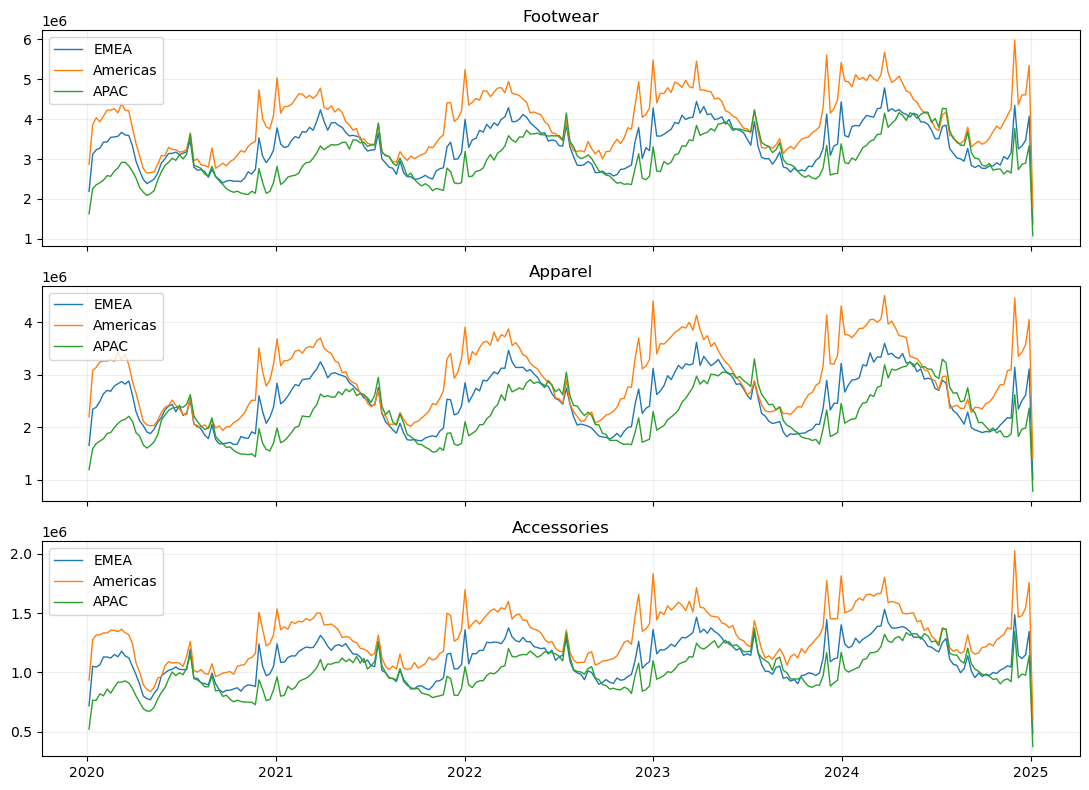

In [2]:
weekly = (df.set_index('date')
          .groupby(['category', 'region'])['revenue']
          .resample('W').sum()
          .reset_index())

fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for ax, cat in zip(axes, cfg.data.categories):
    for reg in cfg.data.regions:
        sub = weekly[(weekly['category'] == cat) & (weekly['region'] == reg)]
        ax.plot(sub['date'], sub['revenue'], label=reg, linewidth=1)
    ax.set_title(cat)
    ax.legend(loc='upper left')
    ax.grid(alpha=0.2)
plt.tight_layout();

## 2. Forecast with prediction intervals

We fit a LightGBM quantile forecaster at q10/q50/q90 and roll it out recursively over a 28-day horizon.

In [3]:
from fin_copilot.forecasting.model import QuantileForecaster

train = df[df['date'] <= '2024-12-03']
model = QuantileForecaster(quantiles=cfg.forecast.quantiles, params=cfg.forecast.lgbm).fit(train)
forecast = model.predict_recursive(train, horizon_days=28)
forecast.head()

,category,region,date,q10,q50,q90,point
0,Accessories,APAC,2024-12-04,"130,348.91","137,381.46","149,124.03","137,381.46"
1,Accessories,APAC,2024-12-05,"131,685.02","139,430.09","148,715.98","139,430.09"
2,Accessories,APAC,2024-12-06,"134,383.80","139,310.37","146,212.31","139,310.37"
3,Accessories,APAC,2024-12-07,"138,991.93","148,781.96","154,731.15","148,781.96"
4,Accessories,APAC,2024-12-08,"140,798.75","144,109.91","150,266.64","144,109.91"


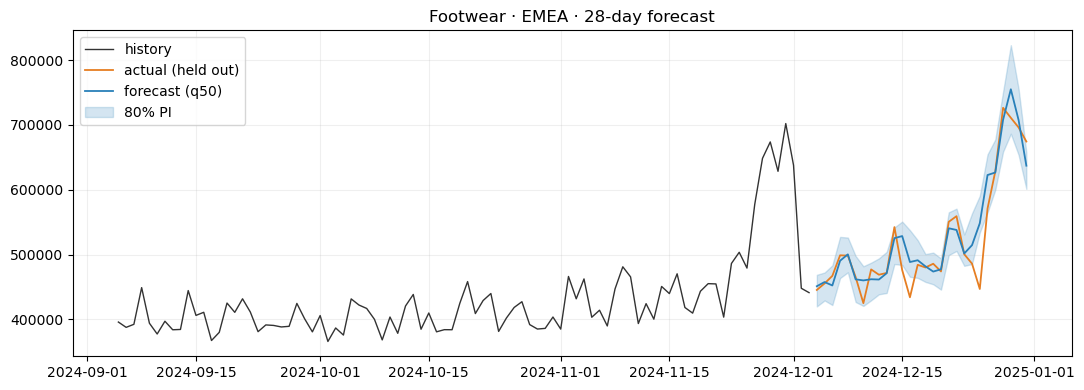

In [4]:
pair = forecast[(forecast['category'] == 'Footwear') & (forecast['region'] == 'EMEA')].sort_values('date')
hist = train[(train['category'] == 'Footwear') & (train['region'] == 'EMEA')].sort_values('date').tail(90)
actual = df[(df['category'] == 'Footwear') & (df['region'] == 'EMEA') & (df['date'] > '2024-12-03')].sort_values('date')

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(hist['date'], hist['revenue'], color='#333', label='history', linewidth=1)
ax.plot(actual['date'], actual['revenue'], color='#e67e22', label='actual (held out)', linewidth=1.3)
ax.plot(pair['date'], pair['point'], color='#2980b9', label='forecast (q50)', linewidth=1.3)
ax.fill_between(pair['date'], pair['q10'], pair['q90'], alpha=0.2, color='#2980b9', label='80% PI')
ax.set_title('Footwear · EMEA · 28-day forecast')
ax.legend();
ax.grid(alpha=0.2);
plt.tight_layout();

## 3. Walk-forward backtest

Six folds, each a 28-day holdout, sliding forward through the final six months.

In [5]:
from fin_copilot.forecasting.backtest import walk_forward
from fin_copilot.evaluation.forecast_metrics import summary_table, per_series_summary

result = walk_forward(df, cfg.forecast, cfg.backtest.n_folds, cfg.backtest.fold_horizon_days)
print(summary_table(result))
per_series_summary(result)

      mape  smape      rmse  pinball_10  pinball_90  coverage_80
mean  5.01   4.96 24,123.52    3,815.42    4,289.67         0.65
std   0.86   0.90  9,369.11      893.97    1,726.28         0.04


,category,region,mape_mean,mape_std,coverage_mean
0,Accessories,APAC,5.40,1.40,0.55
1,Accessories,Americas,5.13,1.02,0.58
2,Accessories,EMEA,4.82,1.03,0.70
3,Apparel,APAC,5.22,1.53,0.68
4,Apparel,Americas,5.07,1.31,0.64
5,Apparel,EMEA,5.07,0.56,0.70
6,Footwear,APAC,4.93,0.83,0.58
7,Footwear,Americas,4.74,1.59,0.65
8,Footwear,EMEA,4.67,0.93,0.73


## 4. Gross-profit scenarios

Starting from the point forecast, we project how a price change and/or cost change would flow through to gross profit, factoring in demand response via a simple elasticity.

In [6]:
from fin_copilot.scenarios.gross_profit import ScenarioParams, run_scenario

pred_full = model.predict_recursive(df, horizon_days=28)
scenarios = {
    'baseline': ScenarioParams(),
    '+5% price / -1.2 elasticity': ScenarioParams(price_change_pct=0.05, price_elasticity=-1.2),
    '+8% COGS': ScenarioParams(cogs_change_pct=0.08),
    '+3% price / +5% COGS / -0.8 elasticity': ScenarioParams(price_change_pct=0.03, cogs_change_pct=0.05, price_elasticity=-0.8),
}
rows = []
for name, params in scenarios.items():
    r = run_scenario(df, pred_full, params)
    s = r.summary()
    rows.append({'scenario': name, **s})
pd.DataFrame(rows).set_index('scenario')[['scenario_revenue','scenario_gross_profit','delta_revenue_pct','delta_gross_profit_pct']]

,scenario_revenue,scenario_gross_profit,delta_revenue_pct,delta_gross_profit_pct
scenario,,,,
baseline,"101,113,375.80","51,763,055.10",0.00,0.00
+5% price / -1.2 elasticity,"99,798,901.91","53,409,600.46",-1.30,3.18
+8% COGS,"101,113,375.80","47,815,029.45",0.00,-7.63
+3% price / +5% COGS / -0.8 elasticity,"101,647,254.42","51,073,045.77",0.53,-1.33


## 5. Agent — grounded answers from the tools

The agent is a LangGraph tool-calling loop that must source every number from a tool call. The default backend is **Ollama** running locally (free, no API key), with `qwen2.5:7b` as the default model. Hosted providers (OpenAI, Anthropic) also work via `FINCOPILOT_MODEL_PROVIDER` env vars.

Below we run three different questions and then score grounding on the final answers.

In [7]:
from fin_copilot.agent.graph import build_agent
from fin_copilot.evaluation.agent_eval import score_grounding

agent = None
try:
    agent = build_agent()
    print('Agent ready via:', type(agent.graph).__name__)
except Exception as e:
    print('Agent not available (set up Ollama or an API key):', e)

Agent ready via: CompiledStateGraph


In [8]:
QUESTIONS = [
    'What categories and regions do you have data for?',
    'What was total Footwear revenue in EMEA for the full year 2024?',
    'If we raise prices by 4% on Apparel in Americas with elasticity -1.2, what happens to gross profit over the next 28 days?',
]

if agent is None:
    print('Skipping — agent unavailable.')
else:
    for q in QUESTIONS:
        print('='*80)
        print('Q:', q)
        out = agent.invoke(q)
        print()
        print('TOOLS CALLED:')
        for tc in out['tool_calls']:
            print(f"  → {tc['name']}({tc['args']})")
        print()
        print('ANSWER:')
        print(out['answer'])
        rep = score_grounding(out['answer'], out['tool_results'])
        print()
        print(f'grounding: {len(rep.grounded)} grounded / {len(rep.hallucinated)} hallucinated '
              f'({rep.hallucination_rate:.0%} hallucination rate)')
        print()

Q: What categories and regions do you have data for?

TOOLS CALLED:
  → list_dimensions({})

ANSWER:
We have data for the following categories: Accessories, Apparel, Footwear. The available regions are: APAC, Americas, EMEA. The data spans from January 1, 2020, to December 31, 2024.

grounding: 4 grounded / 0 hallucinated (0% hallucination rate)

Q: What was total Footwear revenue in EMEA for the full year 2024?

TOOLS CALLED:
  → historical_metric({'end_date': '2024-12-31', 'metric': 'revenue', 'category': 'Footwear', 'region': 'EMEA', 'start_date': '2024-01-01'})

ANSWER:
The total Footwear revenue in EMEA for the full year 2024 was EUR 188,881,621.

grounding: 2 grounded / 0 hallucinated (0% hallucination rate)

Q: If we raise prices by 4% on Apparel in Americas with elasticity -1.2, what happens to gross profit over the next 28 days?

TOOLS CALLED:
  → gross_profit_scenario({'price_change_pct': 0.04, 'price_elasticity': -1.2, 'region': 'Americas', 'volume_change_pct': 0, 'category'